# 🕐 Sesión 10-A: Series de Tiempo con RNN, LSTM y GRU

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR_REPO/blob/main/notebook-semana10-A-rnn-lstm-gru.ipynb)

**Curso:** IS056B — Ingeniería del Conocimiento | UNCP 2026-II
**Unidad II:** Transferencia de Aprendizaje, Series de Tiempo y MLOps
**Docente:** Msc. Jaime Antonio Huaytalla Pariona

---

### Objetivo
Comprender y aplicar las arquitecturas recurrentes (RNN, LSTM, GRU) para el análisis de series de tiempo, desde pronóstico univariado hasta clasificación de señales.

### Estructura del Notebook
| # | Nivel | Tema | Aplicación |
|---|---|---|---|
| 1 | 🟢 Básico | Pronóstico univariado de temperatura | **Forecasting** con LSTM |
| 2 | 🟡 Intermedio | Pronóstico multivariado — LSTM vs GRU | **Forecasting multivariado** + comparación |
| 3 | 🔴 Avanzado | Clasificación de señales | **Clasificación de secuencias** con BiLSTM |

> **Requisitos:** GPU T4 habilitada (Entorno de ejecución → Cambiar tipo de entorno → GPU T4)

In [ ]:
# ============================================================
# 📦 Instalación e importaciones
# ============================================================
!pip install -q statsmodels

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             mean_absolute_error, mean_squared_error)
import time
import warnings
warnings.filterwarnings('ignore')

# Reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)

# Estilo de visualización
sns.set_style('darkgrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12

print(f'TensorFlow: {tf.__version__}')
print(f'NumPy: {np.__version__}')
print(f'Pandas: {pd.__version__}')

TensorFlow: 2.21.0
NumPy: 2.4.6
Pandas: 2.2.3


In [ ]:
# ============================================================
# 🖥️ Verificación de GPU
# ============================================================
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f'✅ GPU disponible: {gpus[0].name}')
    print(f'   Nombre: {tf.test.gpu_device_name()}')
else:
    print('⚠️ No se detectó GPU. El entrenamiento será más lento.')
    print('   Ve a: Entorno de ejecución → Cambiar tipo de entorno → GPU T4')

✅ GPU disponible: /physical_device:GPU:0
   Nombre: /device:GPU:0


## 📋 Recapitulación: RNN vs LSTM vs GRU

| Característica | RNN Simple | LSTM | GRU |
|---|---|---|---|
| **Compuertas** | Ninguna | 3 (Forget, Input, Output) | 2 (Update, Reset) |
| **Estados** | 1 ($h_t$) | 2 ($h_t$ + $C_t$) | 1 ($h_t$) |
| **Vanishing Gradient** | ❌ Severo | ✅ Resuelto | ✅ Resuelto |
| **Secuencias largas** | ~10-20 pasos | ~200+ pasos | ~200+ pasos |
| **Parámetros (64 units)** | ~4K | ~17K | ~13K |
| **Velocidad** | Rápida | Lenta | Intermedia |
| **Mejor para** | Nunca (usar LSTM/GRU) | Secuencias largas, estándar | Recursos limitados |

> **Regla práctica:** Empieza con GRU (más rápido), escala a LSTM si necesitas más capacidad.

In [ ]:
# ============================================================
# 🛠️ Funciones auxiliares
# ============================================================

def create_sequences(data, window_size, horizon=1):
    '''Crea pares (X, y) con ventanas deslizantes.

    Args:
        data: array 1D o 2D (samples, features)
        window_size: pasos temporales de entrada
        horizon: pasos a predecir

    Returns:
        X: array (n_samples, window_size, features)
        y: array (n_samples, horizon) o (n_samples,) si horizon=1
    '''
    if data.ndim == 1:
        data = data.reshape(-1, 1)

    X, y = [], []
    for i in range(len(data) - window_size - horizon + 1):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size:i + window_size + horizon, 0])
    X = np.array(X)
    y = np.array(y)
    if horizon == 1:
        y = y.flatten()
    return X, y


def plot_training_history(history, title='Curvas de Entrenamiento'):
    '''Grafica loss y métricas de un entrenamiento.'''
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Loss
    axes[0].plot(history.history['loss'], label='Train Loss', linewidth=2)
    axes[0].plot(history.history['val_loss'], label='Val Loss', linewidth=2)
    axes[0].set_xlabel('Época')
    axes[0].set_ylabel('Loss (MSE)')
    axes[0].set_title(f'{title} — Loss')
    axes[0].legend()

    # MAE si está disponible
    mae_key = 'mae' if 'mae' in history.history else 'accuracy'
    val_mae_key = 'val_mae' if 'val_mae' in history.history else 'val_accuracy'
    label = 'MAE' if 'mae' in history.history else 'Accuracy'

    if mae_key in history.history:
        axes[1].plot(history.history[mae_key], label=f'Train {label}', linewidth=2)
        axes[1].plot(history.history[val_mae_key], label=f'Val {label}', linewidth=2)
        axes[1].set_xlabel('Época')
        axes[1].set_ylabel(label)
        axes[1].set_title(f'{title} — {label}')
        axes[1].legend()

    plt.tight_layout()
    plt.show()


def evaluate_forecast(y_true, y_pred):
    '''Calcula métricas de pronóstico.'''
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    # MAPE: evitar división por cero
    mask = y_true != 0
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    return {'MAE': mae, 'RMSE': rmse, 'MAPE': mape}


# Paleta de colores consistente
COLORS = {
    'lstm': '#2196F3',
    'gru': '#FF9800',
    'rnn': '#F44336',
    'bilstm': '#4CAF50',
    'actual': '#263238',
    'naive': '#9E9E9E',
    'pred': '#E91E63'
}

print('✅ Funciones auxiliares cargadas')

✅ Funciones auxiliares cargadas


---

## 🌡️ Ejemplo 1 (Básico): Pronóstico Univariado de Temperatura

**Objetivo:** Construir un modelo LSTM que prediga la temperatura una hora adelante, usando solo el historial de temperatura.

**Dataset:** [Jena Climate](https://www.bgc-jena.mpg.de/wetter/) — Mediciones meteorológicas cada 10 minutos desde 2009 hasta 2016 en Jena, Alemania. Es el dataset estándar para aprender series de tiempo con deep learning.

**Tarea:** Forecasting univariado (many-to-one)

**Pasos:**
1. Exploración y descomposición de la serie
2. Preprocesamiento: submuestreo, split cronológico, normalización
3. Creación de ventanas deslizantes
4. Modelo LSTM simple
5. Evaluación contra baseline naive

In [ ]:
# ============================================================
# 📥 Descarga del dataset Jena Climate
# ============================================================
import os

zip_path = tf.keras.utils.get_file(
    origin='https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip',
    fname='jena_climate_2009_2016.csv.zip',
    extract=True
)

# La carpeta extraída contiene el archivo CSV directamente dentro
extracted_dir = zip_path.replace('.zip', '')
csv_path = os.path.join(extracted_dir, 'jena_climate_2009_2016.csv')

df_jena = pd.read_csv(csv_path)

print(f'Shape del dataset: {df_jena.shape}')
print(f'Rango temporal: {df_jena["Date Time"].iloc[0]} → {df_jena["Date Time"].iloc[-1]}')
print(f'Frecuencia: cada 10 minutos')
print(f'\nColumnas disponibles ({len(df_jena.columns)}):')
for col in df_jena.columns:
    print(f'  • {col}')

df_jena.head()

Shape del dataset: (420551, 15)
Rango temporal: 01.01.2009 00:10:00 → 01.01.2017 00:00:00
Frecuencia: cada 10 minutos

Columnas disponibles (15):
  • Date Time
  • p (mbar)
  • T (degC)
  • Tpot (K)
  • Tdew (degC)
  • rh (%)
  • VPmax (mbar)
  • VPact (mbar)
  • VPdef (mbar)
  • sh (g/kg)
  • H2OC (mmol/mol)
  • rho (g/m**3)
  • wv (m/s)
  • max. wv (m/s)
  • wd (deg)


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


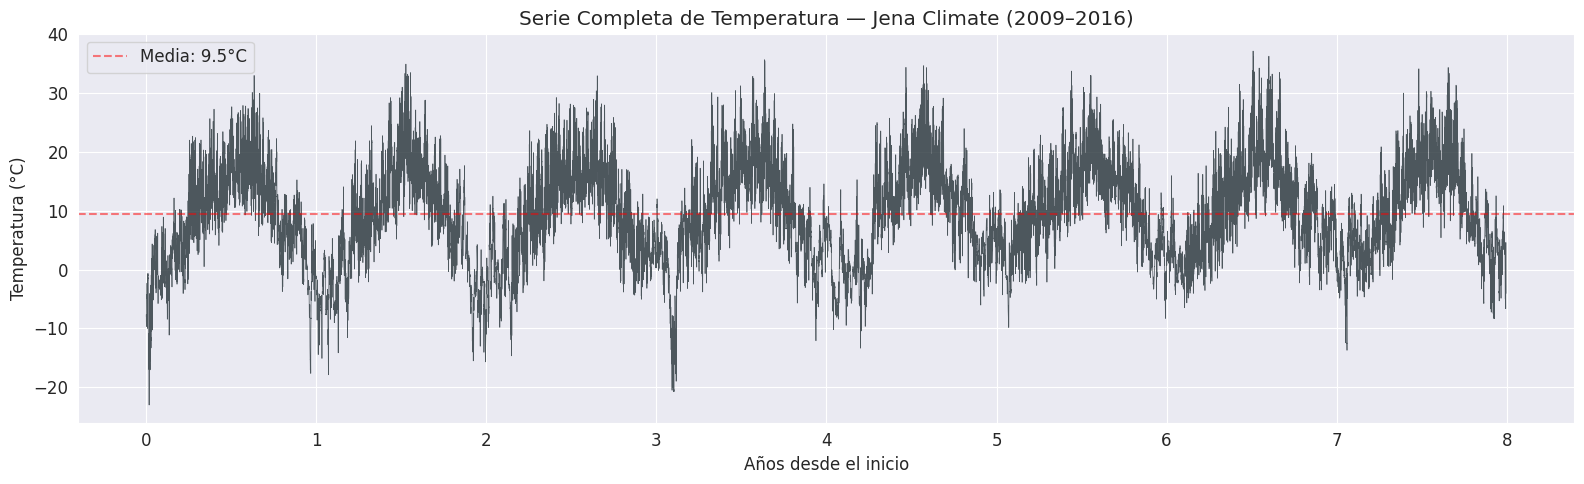

Estadísticas de temperatura:
  Mínima: -23.0°C | Máxima: 37.3°C | Media: 9.5°C


In [ ]:
# ============================================================
# 📈 Visualización de la serie completa de temperatura
# ============================================================
fig, ax = plt.subplots(figsize=(16, 5))

temp = df_jena['T (degC)'].values
n_points = len(temp)

# Subsamplear para plotear (cada hora)
plot_idx = np.arange(0, n_points, 6)
ax.plot(plot_idx / (6 * 24 * 365.25), temp[plot_idx],
        linewidth=0.5, color=COLORS['actual'], alpha=0.8)
ax.set_xlabel('Años desde el inicio')
ax.set_ylabel('Temperatura (°C)')
ax.set_title('Serie Completa de Temperatura — Jena Climate (2009–2016)')
ax.axhline(y=temp.mean(), color='red', linestyle='--', alpha=0.5,
           label=f'Media: {temp.mean():.1f}°C')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Estadísticas de temperatura:')
print(f'  Mínima: {temp.min():.1f}°C | Máxima: {temp.max():.1f}°C | Media: {temp.mean():.1f}°C')

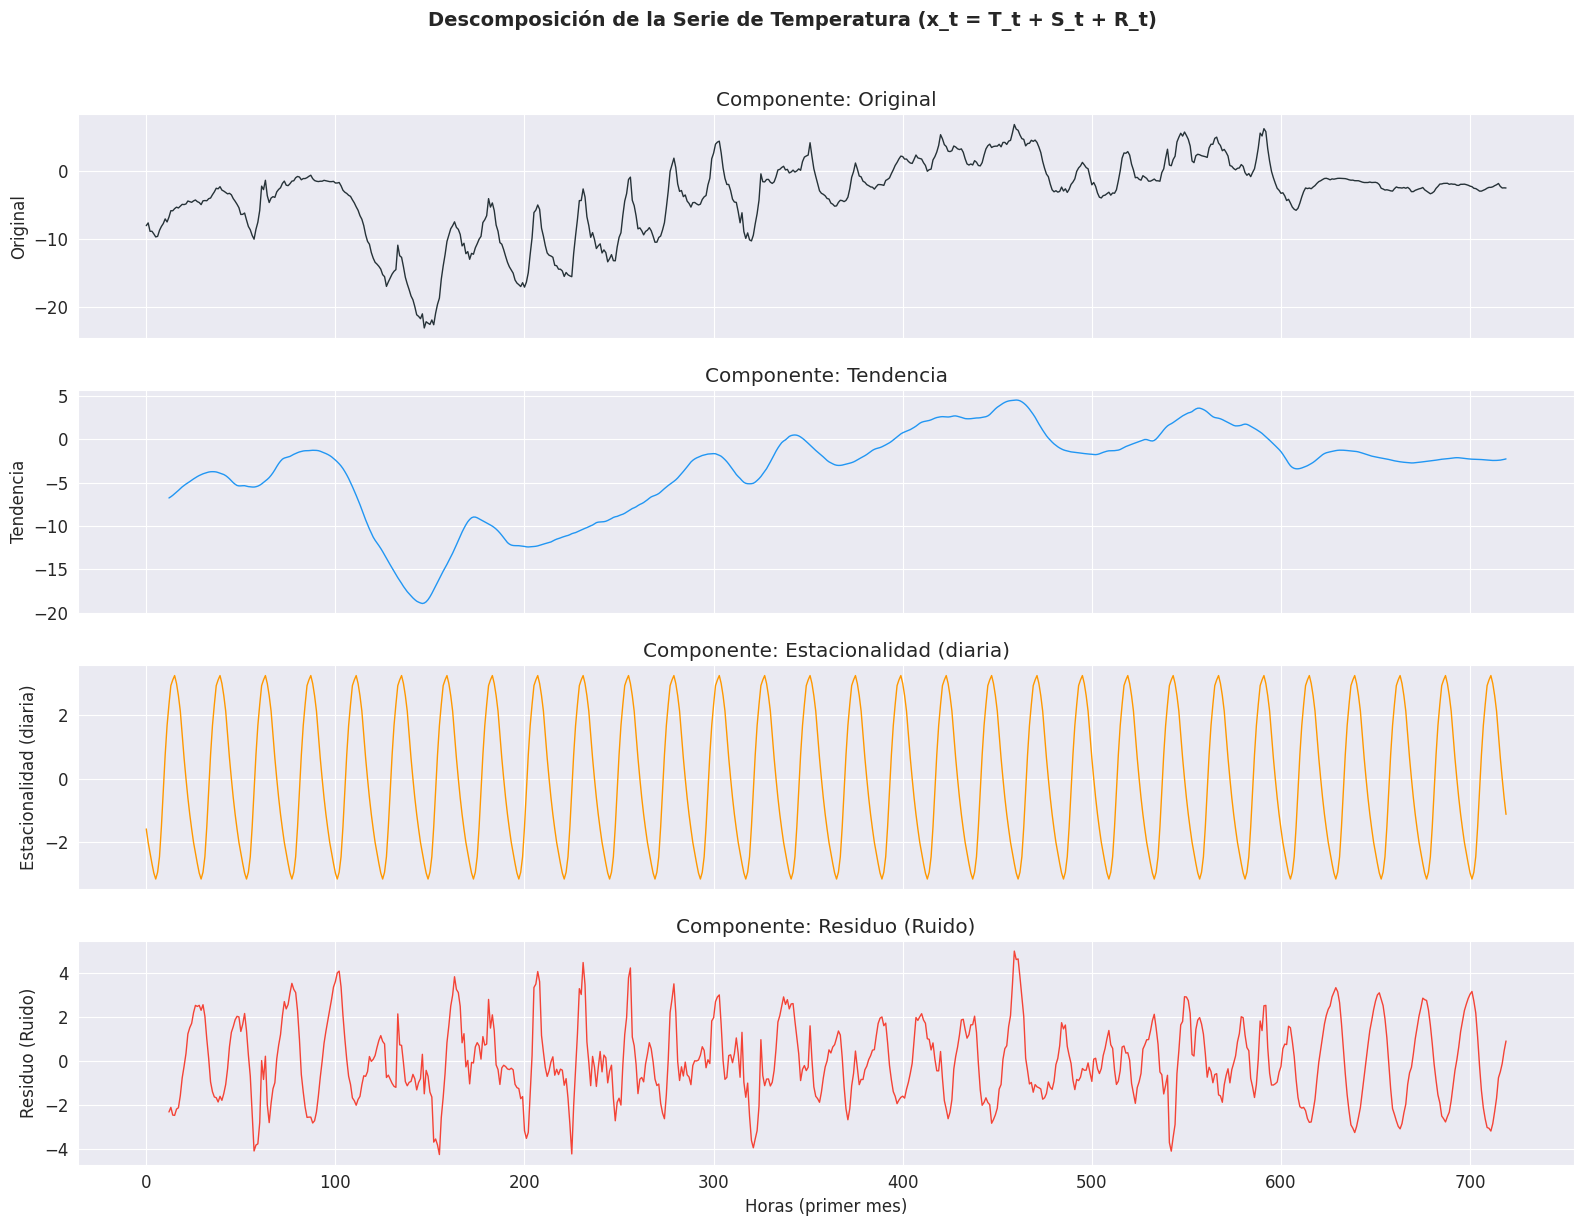

✅ Se observa claramente:
   • Tendencia: variación estacional anual
   • Estacionalidad diaria: ciclo día/noche (~24h)
   • Residuo: variaciones aleatorias del clima


In [ ]:
# ============================================================
# 📊 Descomposición estacional
# ============================================================
from statsmodels.tsa.seasonal import seasonal_decompose

# Tomar un año de datos horarios para la descomposición
temp_hourly_sample = temp[::6][:8760]  # 1 año ≈ 8760 horas

decomposition = seasonal_decompose(
    temp_hourly_sample,
    model='additive',
    period=24  # Período diario (24 horas)
)

fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)
components = [
    ('Original', temp_hourly_sample, COLORS['actual']),
    ('Tendencia', decomposition.trend, COLORS['lstm']),
    ('Estacionalidad (diaria)', decomposition.seasonal, COLORS['gru']),
    ('Residuo (Ruido)', decomposition.resid, COLORS['rnn'])
]

for ax, (name, data, color) in zip(axes, components):
    ax.plot(data[:720], color=color, linewidth=1)  # Primer mes
    ax.set_ylabel(name)
    ax.set_title(f'Componente: {name}')

axes[-1].set_xlabel('Horas (primer mes)')
fig.suptitle('Descomposición de la Serie de Temperatura (x_t = T_t + S_t + R_t)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('✅ Se observa claramente:')
print('   • Tendencia: variación estacional anual')
print('   • Estacionalidad diaria: ciclo día/noche (~24h)')
print('   • Residuo: variaciones aleatorias del clima')

### 🔧 Preprocesamiento — Las 3 Reglas de Oro

1. **Submuestreo horario**: Los datos están cada 10 min (420K filas). Submuestreamos a cada hora (~70K filas) para hacer el entrenamiento manejable sin perder la estructura temporal.

2. **Split cronológico (NUNCA aleatorio)**: Usamos el primer 80% para entrenamiento y el 20% final para test. Mezclar aleatoriamente crearía **fuga de datos temporal** (data leakage).

3. **Normalización con fit SOLO en train**: El `MinMaxScaler` aprende los rangos solo de los datos de entrenamiento. Si usáramos todo el dataset, el modelo "vería" información futura durante el entrenamiento.

```
INCORRECTO:  scaler.fit_transform(todo_el_dataset)  ← ¡Data leakage!
CORRECTO:    scaler.fit(train); scaler.transform(train); scaler.transform(test)
```

Datos originales: 420,551 (cada 10 min)
Datos horarios:   70,092 (cada hora)

Split cronológico:
  Train: 56,073 horas (6.4 años)
  Test:  14,019 horas (1.6 años)

Rango normalizado: [0.000, 1.000]


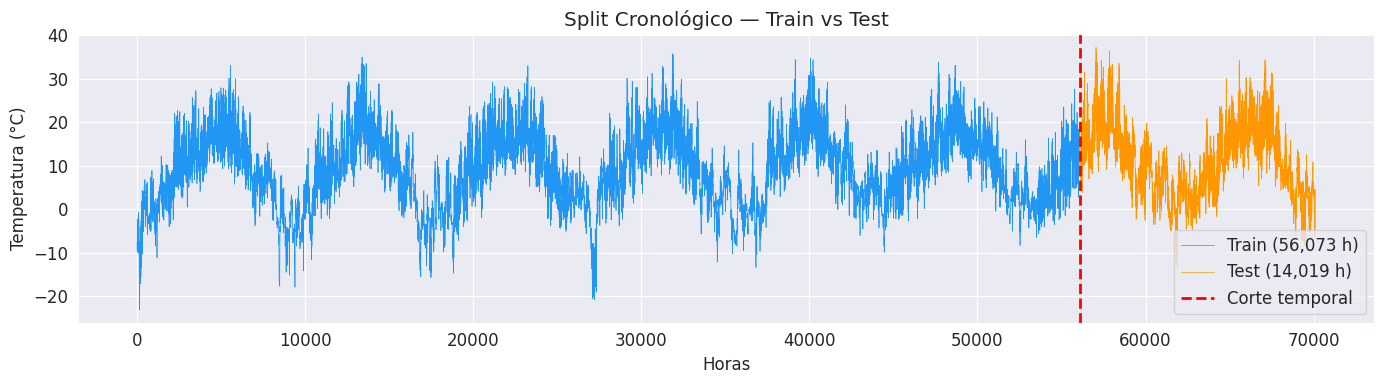

In [ ]:
# ============================================================
# 🔧 Preprocesamiento
# ============================================================

# 1. Submuestreo horario (cada 6 filas → cada hora)
temp_hourly = temp[::6].copy()
print(f'Datos originales: {len(temp):,} (cada 10 min)')
print(f'Datos horarios:   {len(temp_hourly):,} (cada hora)')

# 2. Split cronológico 80/20
split_idx = int(len(temp_hourly) * 0.8)
train_data = temp_hourly[:split_idx]
test_data = temp_hourly[split_idx:]

print(f'\nSplit cronológico:')
print(f'  Train: {len(train_data):,} horas ({len(train_data)/(24*365.25):.1f} años)')
print(f'  Test:  {len(test_data):,} horas ({len(test_data)/(24*365.25):.1f} años)')

# 3. Normalización — fit SOLO en train
scaler_uni = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler_uni.fit_transform(train_data.reshape(-1, 1)).flatten()
test_scaled = scaler_uni.transform(test_data.reshape(-1, 1)).flatten()

print(f'\nRango normalizado: [{train_scaled.min():.3f}, {train_scaled.max():.3f}]')

# Visualizar split
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(range(len(train_data)), train_data, color=COLORS['lstm'],
        label=f'Train ({len(train_data):,} h)', linewidth=0.5)
ax.plot(range(len(train_data), len(temp_hourly)), test_data, color=COLORS['gru'],
        label=f'Test ({len(test_data):,} h)', linewidth=0.5)
ax.axvline(x=split_idx, color='red', linestyle='--', linewidth=2, label='Corte temporal')
ax.set_xlabel('Horas')
ax.set_ylabel('Temperatura (°C)')
ax.set_title('Split Cronológico — Train vs Test')
ax.legend()
plt.tight_layout()
plt.show()

Ventana: 72 horas (3 días) → Predecir: 1 hora

Shapes:
  X_train: (56001, 72, 1)  (muestras, pasos, features)
  y_train: (56001,)
  X_test:  (13947, 72, 1)
  y_test:  (13947,)


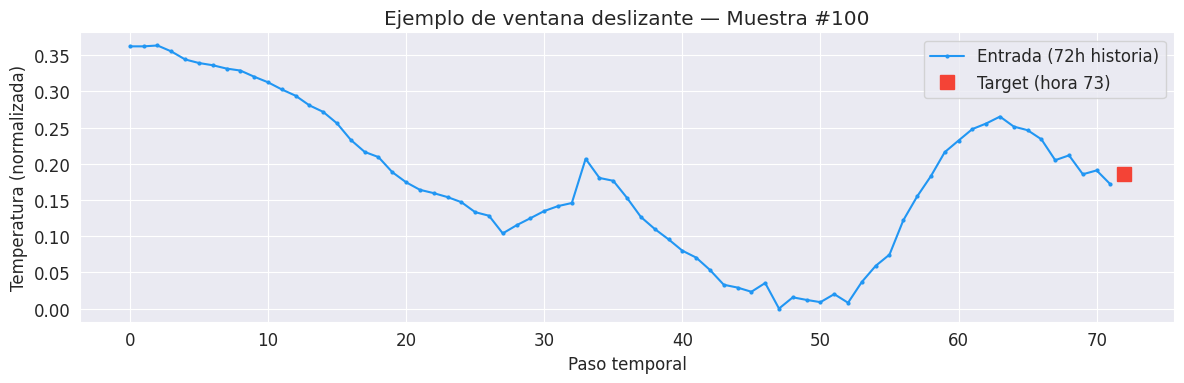

In [ ]:
# ============================================================
# 🪟 Creación de ventanas deslizantes
# ============================================================
WINDOW_SIZE = 72   # 72 horas = 3 días de historia
HORIZON = 1        # Predecir 1 hora adelante

X_train_uni, y_train_uni = create_sequences(train_scaled, WINDOW_SIZE, HORIZON)
X_test_uni, y_test_uni = create_sequences(test_scaled, WINDOW_SIZE, HORIZON)

print(f'Ventana: {WINDOW_SIZE} horas (3 días) → Predecir: {HORIZON} hora')
print(f'\nShapes:')
print(f'  X_train: {X_train_uni.shape}  (muestras, pasos, features)')
print(f'  y_train: {y_train_uni.shape}')
print(f'  X_test:  {X_test_uni.shape}')
print(f'  y_test:  {y_test_uni.shape}')

# Visualizar una ventana de ejemplo
fig, ax = plt.subplots(figsize=(12, 4))
sample_idx = 100
window = X_train_uni[sample_idx, :, 0]
target = y_train_uni[sample_idx]
ax.plot(range(WINDOW_SIZE), window, 'o-', color=COLORS['lstm'],
        markersize=2, label='Entrada (72h historia)')
ax.plot(WINDOW_SIZE, target, 's', color=COLORS['rnn'],
        markersize=10, label=f'Target (hora {WINDOW_SIZE+1})')
ax.set_xlabel('Paso temporal')
ax.set_ylabel('Temperatura (normalizada)')
ax.set_title(f'Ejemplo de ventana deslizante — Muestra #{sample_idx}')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 🏗️ Modelo LSTM Simple
# ============================================================
tf.random.set_seed(42)

model_lstm_basic = models.Sequential([
    layers.LSTM(64, input_shape=(WINDOW_SIZE, 1), name='lstm_64'),
    layers.Dropout(0.2, name='dropout'),
    layers.Dense(1, name='salida')
], name='LSTM_Basico')

model_lstm_basic.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

model_lstm_basic.summary()

# Contar parámetros
total_params = model_lstm_basic.count_params()
trainable_params = sum(
    tf.keras.backend.count_params(w) for w in model_lstm_basic.trainable_weights
)
print(f'\n📊 Parámetros totales: {total_params:,}')
print(f'   Parámetros entrenables: {trainable_params:,}')

Model: "LSTM_Basico"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_64 (LSTM)                  │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)


📊 Parámetros totales: 16,961
   Parámetros entrenables: 16,961


Entrenando LSTM básico...
Epoch 1/30
744/744 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - loss: 0.0081 - mae: 0.0593 - val_loss: 9.3847e-04 - val_mae: 0.0226 - learning_rate: 0.0010
Epoch 2/30
744/744 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0020 - mae: 0.0348 - val_loss: 6.8365e-04 - val_mae: 0.0192 - learning_rate: 0.0010
Epoch 3/30
744/744 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0016 - mae: 0.0306 - val_loss: 5.7420e-04 - val_mae: 0.0181 - learning_rate: 0.0010
Epoch 4/30
744/744 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.0012 - mae: 0.0268 - val_loss: 5.0255e-04 - val_mae: 0.0165 - learning_rate: 0.0010
Epoch 5/30
744/744 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 9.2197e-04 - mae: 0.0231 - val_loss: 3.1325e-04 - val_mae: 0.0128 - learning_rate: 0.0010
Epoch 6/30
744/744 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 6.8789e-04 - mae: 0.0197 - val_loss: 2.6562e-04 - val_mae: 0.0115 - learning_rate: 0.0010
Epoch 7/30
744/744 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 5.2180e-04 - mae: 0.0170 - val

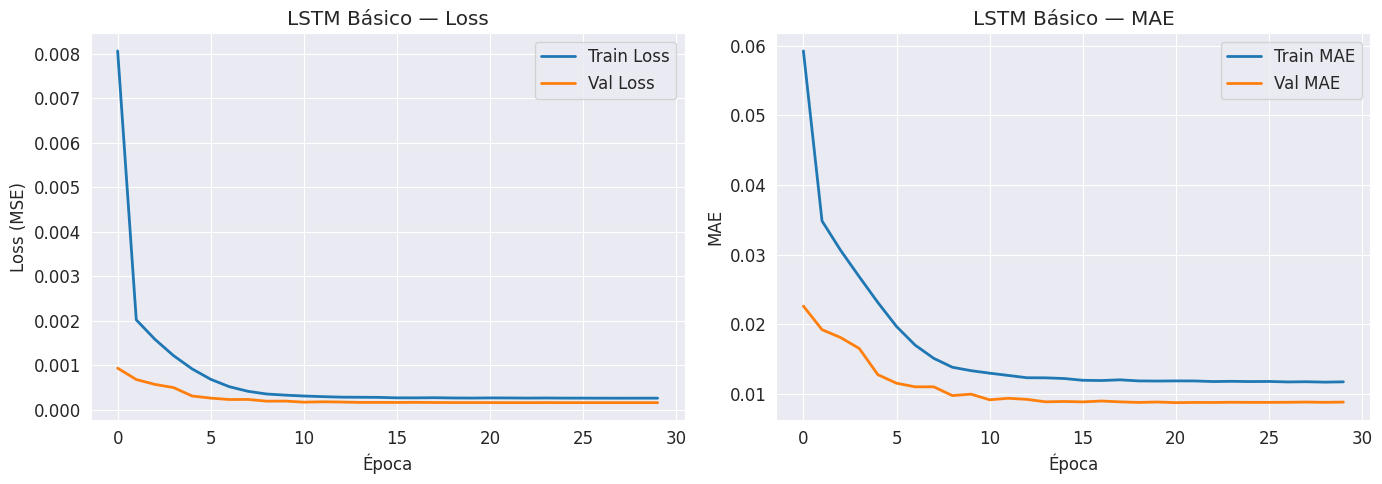

In [ ]:
# ============================================================
# 🚀 Entrenamiento del LSTM
# ============================================================
EPOCHS = 30
BATCH_SIZE = 64

cb_list = [
    callbacks.EarlyStopping(patience=5, restore_best_weights=True,
                            monitor='val_loss', verbose=1),
    callbacks.ReduceLROnPlateau(factor=0.5, patience=3,
                                monitor='val_loss', verbose=1)
]

print('Entrenando LSTM básico...')
t0 = time.time()
history_basic = model_lstm_basic.fit(
    X_train_uni, y_train_uni,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.15,
    callbacks=cb_list,
    verbose=1
)
time_lstm_basic = time.time() - t0
print(f'\n⏱️ Tiempo de entrenamiento: {time_lstm_basic:.1f} segundos')

plot_training_history(history_basic, 'LSTM Básico')

In [ ]:
# ============================================================
# 📏 Evaluación vs Baseline Naive
# ============================================================

# Predicciones del modelo
y_pred_basic = model_lstm_basic.predict(X_test_uni, verbose=0).flatten()

# Baseline naive: predecir el último valor conocido de la ventana
y_naive = X_test_uni[:, -1, 0]

# Desnormalizar para métricas interpretables
y_test_real = scaler_uni.inverse_transform(y_test_uni.reshape(-1, 1)).flatten()
y_pred_real = scaler_uni.inverse_transform(y_pred_basic.reshape(-1, 1)).flatten()
y_naive_real = scaler_uni.inverse_transform(y_naive.reshape(-1, 1)).flatten()

# Métricas
metrics_lstm = evaluate_forecast(y_test_real, y_pred_real)
metrics_naive = evaluate_forecast(y_test_real, y_naive_real)

print('=' * 60)
print('COMPARACIÓN: LSTM vs Baseline Naive')
print('=' * 60)
print(f'{"":<15} {"MAE (°C)":<15} {"RMSE (°C)":<15} {"MAPE (%)":<15}')
print('-' * 60)
print(f'{"Naive":<15} {metrics_naive["MAE"]:<15.4f} {metrics_naive["RMSE"]:<15.4f} {metrics_naive["MAPE"]:<15.2f}')
print(f'{"LSTM":<15} {metrics_lstm["MAE"]:<15.4f} {metrics_lstm["RMSE"]:<15.4f} {metrics_lstm["MAPE"]:<15.2f}')
print('-' * 60)

improvement = (1 - metrics_lstm['MAE'] / metrics_naive['MAE']) * 100
print(f'\n✅ El LSTM mejora el MAE en {improvement:.1f}% respecto al baseline naive')

COMPARACIÓN: LSTM vs Baseline Naive
                MAE (°C)        RMSE (°C)       MAPE (%)       
------------------------------------------------------------
Naive           0.7189          1.0143          18.71          
LSTM            0.5114          0.7398          15.12          
------------------------------------------------------------

✅ El LSTM mejora el MAE en 28.9% respecto al baseline naive


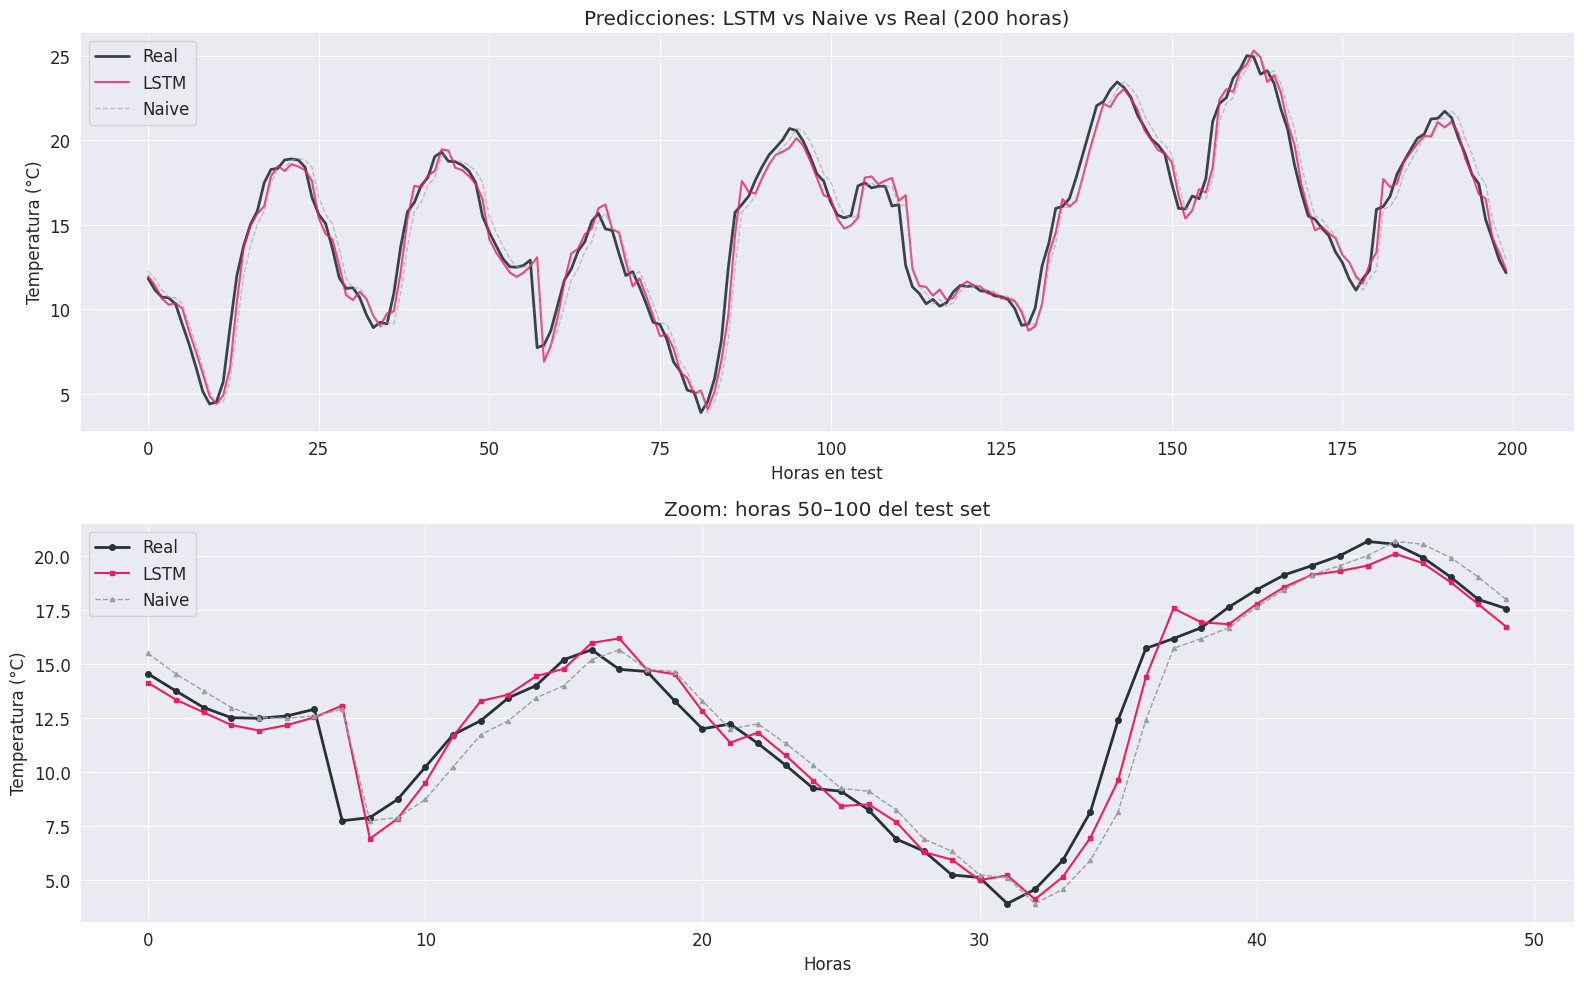

In [ ]:
# ============================================================
# 📊 Visualización de predicciones
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Subplot 1: Primeros 200 puntos
n_show = 200
axes[0].plot(y_test_real[:n_show], color=COLORS['actual'],
             linewidth=2, label='Real', alpha=0.9)
axes[0].plot(y_pred_real[:n_show], color=COLORS['pred'],
             linewidth=1.5, label='LSTM', alpha=0.8)
axes[0].plot(y_naive_real[:n_show], color=COLORS['naive'],
             linewidth=1, linestyle='--', label='Naive', alpha=0.6)
axes[0].set_ylabel('Temperatura (°C)')
axes[0].set_title('Predicciones: LSTM vs Naive vs Real (200 horas)')
axes[0].legend()
axes[0].set_xlabel('Horas en test')

# Subplot 2: Zoom en 50 puntos
n_zoom = 50
start = 50
axes[1].plot(range(n_zoom), y_test_real[start:start+n_zoom],
             'o-', color=COLORS['actual'], linewidth=2,
             markersize=4, label='Real')
axes[1].plot(range(n_zoom), y_pred_real[start:start+n_zoom],
             's-', color=COLORS['pred'], linewidth=1.5,
             markersize=3, label='LSTM')
axes[1].plot(range(n_zoom), y_naive_real[start:start+n_zoom],
             '^--', color=COLORS['naive'], linewidth=1,
             markersize=3, label='Naive')
axes[1].set_ylabel('Temperatura (°C)')
axes[1].set_xlabel('Horas')
axes[1].set_title(f'Zoom: horas {start}–{start+n_zoom} del test set')
axes[1].legend()

plt.tight_layout()
plt.show()

### 💡 Conclusiones del Ejemplo 1

1. **LSTM supera al baseline naive** — Aunque la mejora parece modesta, el baseline naive es sorprendentemente difícil de superar en pronóstico a 1 paso.
2. **Normalización obligatoria** — Sin ella, las funciones sigmoid/tanh de LSTM saturan y los gradientes desaparecen.
3. **Split cronológico** — Nunca usar `train_test_split(shuffle=True)` con series de tiempo.
4. **EarlyStopping** — Evitó sobreajuste deteniendo el entrenamiento en la época óptima.

> ⚡ **Pregunta para reflexionar:** ¿Qué pasaría si usáramos más variables meteorológicas (presión, humedad, viento) además de la temperatura?

---

## 📊 Ejemplo 2 (Intermedio): Pronóstico Multivariado — LSTM vs GRU

**Objetivo:** Comparar LSTM y GRU en pronóstico multivariado, usando múltiples variables meteorológicas para predecir la temperatura.

**Hipótesis:** Las variables correlacionadas (presión, humedad, viento) deberían mejorar la predicción respecto al enfoque univariado.

**Adicionalmente:** Experimentar con diferentes tamaños de ventana para encontrar el *sweet spot*.

**Tarea:** Forecasting multivariado (many-to-one)

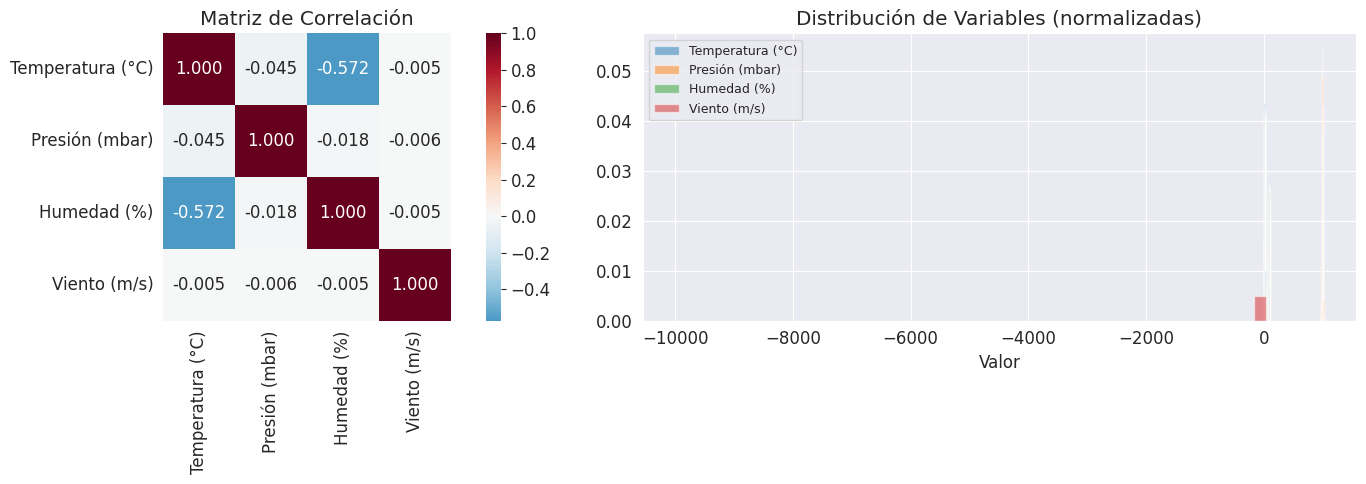

📊 Correlaciones con Temperatura:
   Presión (mbar): -0.045
   Humedad (%): -0.572
   Viento (m/s): -0.005


In [ ]:
# ============================================================
# 🔗 Análisis de correlación entre variables meteorológicas
# ============================================================

# Seleccionar 4 features relevantes
selected_features = ['T (degC)', 'p (mbar)', 'rh (%)', 'wv (m/s)']
feature_names_es = ['Temperatura (°C)', 'Presión (mbar)', 'Humedad (%)', 'Viento (m/s)']

df_multi = df_jena[selected_features].copy()

# Heatmap de correlación
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Correlación
corr_matrix = df_multi.corr()
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0,
            xticklabels=feature_names_es, yticklabels=feature_names_es,
            ax=axes[0], fmt='.3f', square=True)
axes[0].set_title('Matriz de Correlación')

# Distribuciones
for i, (col, name) in enumerate(zip(selected_features, feature_names_es)):
    axes[1].hist(df_multi[col].values[::6], bins=50, alpha=0.5, label=name, density=True)
axes[1].set_title('Distribución de Variables (normalizadas)')
axes[1].legend(fontsize=9)
axes[1].set_xlabel('Valor')

plt.tight_layout()
plt.show()

print('📊 Correlaciones con Temperatura:')
for feat, name in zip(selected_features[1:], feature_names_es[1:]):
    print(f'   {name}: {corr_matrix.loc["T (degC)", feat]:.3f}')

In [ ]:
# ============================================================
# 🔧 Preparación de datos multivariados
# ============================================================

# Extraer features y submuestrear a horario
multi_data = df_jena[selected_features].values[::6]
print(f'Datos multivariados: {multi_data.shape} (horas, features)')

# Split cronológico 80/20
split_multi = int(len(multi_data) * 0.8)
train_multi = multi_data[:split_multi]
test_multi = multi_data[split_multi:]

# Normalizar CADA feature — fit solo en train
scaler_multi = MinMaxScaler()
train_multi_scaled = scaler_multi.fit_transform(train_multi)
test_multi_scaled = scaler_multi.transform(test_multi)

# Crear secuencias multivariadas (predicir solo temperatura = columna 0)
WINDOW_MULTI = 72
X_train_m, y_train_m = create_sequences(train_multi_scaled, WINDOW_MULTI, 1)
X_test_m, y_test_m = create_sequences(test_multi_scaled, WINDOW_MULTI, 1)

print(f'\nShapes multivariados:')
print(f'  X_train: {X_train_m.shape}  (muestras, {WINDOW_MULTI} pasos, {len(selected_features)} features)')
print(f'  y_train: {y_train_m.shape}  (predecir solo temperatura)')
print(f'  X_test:  {X_test_m.shape}')
print(f'  y_test:  {y_test_m.shape}')

# Guardar scaler de temperatura para desnormalizar
temp_min = scaler_multi.data_min_[0]
temp_max = scaler_multi.data_max_[0]
print(f'\nRango de temperatura: [{temp_min:.1f}, {temp_max:.1f}] °C')

Datos multivariados: (70092, 4) (horas, features)

Shapes multivariados:
  X_train: (56001, 72, 4)  (muestras, 72 pasos, 4 features)
  y_train: (56001,)  (predecir solo temperatura)
  X_test:  (13947, 72, 4)
  y_test:  (13947,)

Rango de temperatura: [-23.0, 35.6] °C


In [ ]:
# ============================================================
# 🏗️ Modelo LSTM Stacked (apilado) — Multivariado
# ============================================================
tf.random.set_seed(42)

model_lstm_multi = models.Sequential([
    layers.LSTM(128, return_sequences=True,
                input_shape=(WINDOW_MULTI, len(selected_features)),
                name='lstm_128'),
    layers.Dropout(0.3, name='drop_1'),
    layers.LSTM(64, name='lstm_64'),
    layers.Dropout(0.2, name='drop_2'),
    layers.Dense(32, activation='relu', name='dense_32'),
    layers.Dense(1, name='salida')
], name='LSTM_Stacked_Multi')

model_lstm_multi.compile(optimizer='adam', loss='mse', metrics=['mae'])

print('=== LSTM Stacked Multivariado ===')
model_lstm_multi.summary()
lstm_params = model_lstm_multi.count_params()
print(f'\nTotal parámetros: {lstm_params:,}')

=== LSTM Stacked Multivariado ===


Model: "LSTM_Stacked_Multi"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_128 (LSTM)                 │ (None, 72, 128)        │        68,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 72, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_64 (LSTM)                  │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_2 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 119,617 (467.25 KB)

 Trainable params: 119,617 (467.25 KB)

 Non-trainable params: 0 (0.00 B)


Total parámetros: 119,617


In [ ]:
# ============================================================
# 🏗️ Modelo GRU Stacked (apilado) — Multivariado
# ============================================================
tf.random.set_seed(42)

model_gru_multi = models.Sequential([
    layers.GRU(128, return_sequences=True,
               input_shape=(WINDOW_MULTI, len(selected_features)),
               name='gru_128'),
    layers.Dropout(0.3, name='drop_1'),
    layers.GRU(64, name='gru_64'),
    layers.Dropout(0.2, name='drop_2'),
    layers.Dense(32, activation='relu', name='dense_32'),
    layers.Dense(1, name='salida')
], name='GRU_Stacked_Multi')

model_gru_multi.compile(optimizer='adam', loss='mse', metrics=['mae'])

print('=== GRU Stacked Multivariado ===')
model_gru_multi.summary()
gru_params = model_gru_multi.count_params()
print(f'\nTotal parámetros: {gru_params:,}')
print(f'\n📊 Diferencia: LSTM tiene {lstm_params - gru_params:,} parámetros más que GRU')
print(f'   GRU es {(1 - gru_params/lstm_params)*100:.1f}% más ligero')

=== GRU Stacked Multivariado ===


Model: "GRU_Stacked_Multi"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_128 (GRU)                   │ (None, 72, 128)        │        51,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 72, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_64 (GRU)                    │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_2 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,817 (354.75 KB)

 Trainable params: 90,817 (354.75 KB)

 Non-trainable params: 0 (0.00 B)


Total parámetros: 90,817

📊 Diferencia: LSTM tiene 28,800 parámetros más que GRU
   GRU es 24.1% más ligero


In [ ]:
# ============================================================
# 🚀 Entrenamiento de ambos modelos
# ============================================================
EPOCHS = 30
BATCH_SIZE = 64

cb_factory = lambda: [
    callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=0),
    callbacks.ReduceLROnPlateau(factor=0.5, patience=3, verbose=0)
]

# Entrenar LSTM
print('🔵 Entrenando LSTM Stacked...')
t0 = time.time()
hist_lstm_m = model_lstm_multi.fit(
    X_train_m, y_train_m,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_split=0.15, callbacks=cb_factory(), verbose=0
)
time_lstm_m = time.time() - t0
print(f'   ⏱️ {time_lstm_m:.1f}s | Mejor val_loss: {min(hist_lstm_m.history["val_loss"]):.6f}')

# Entrenar GRU
print('🟠 Entrenando GRU Stacked...')
t0 = time.time()
hist_gru_m = model_gru_multi.fit(
    X_train_m, y_train_m,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    validation_split=0.15, callbacks=cb_factory(), verbose=0
)
time_gru_m = time.time() - t0
print(f'   ⏱️ {time_gru_m:.1f}s | Mejor val_loss: {min(hist_gru_m.history["val_loss"]):.6f}')

print(f'\n⚡ GRU fue {time_lstm_m/time_gru_m:.1f}x más rápido que LSTM')

🔵 Entrenando LSTM Stacked...
   ⏱️ 193.0s | Mejor val_loss: 0.002195
🟠 Entrenando GRU Stacked...
   ⏱️ 121.5s | Mejor val_loss: 0.000223

⚡ GRU fue 1.6x más rápido que LSTM


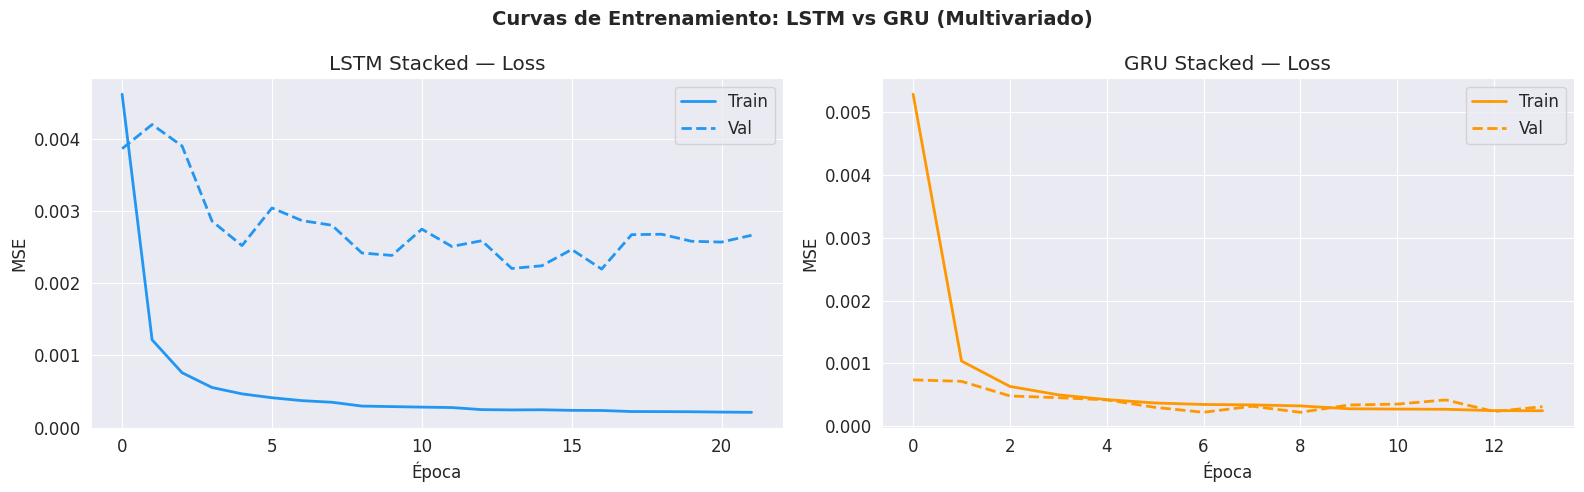

In [ ]:
# ============================================================
# 📉 Curvas de entrenamiento — LSTM vs GRU
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# LSTM
axes[0].plot(hist_lstm_m.history['loss'], color=COLORS['lstm'],
             label='Train', linewidth=2)
axes[0].plot(hist_lstm_m.history['val_loss'], color=COLORS['lstm'],
             linestyle='--', label='Val', linewidth=2)
axes[0].set_title('LSTM Stacked — Loss')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('MSE')
axes[0].legend()

# GRU
axes[1].plot(hist_gru_m.history['loss'], color=COLORS['gru'],
             label='Train', linewidth=2)
axes[1].plot(hist_gru_m.history['val_loss'], color=COLORS['gru'],
             linestyle='--', label='Val', linewidth=2)
axes[1].set_title('GRU Stacked — Loss')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('MSE')
axes[1].legend()

plt.suptitle('Curvas de Entrenamiento: LSTM vs GRU (Multivariado)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 📏 Comparación de predicciones LSTM vs GRU
# ============================================================

# Predicciones
pred_lstm_m = model_lstm_multi.predict(X_test_m, verbose=0).flatten()
pred_gru_m = model_gru_multi.predict(X_test_m, verbose=0).flatten()

# Desnormalizar (temperatura es la columna 0)
def denorm_temp(values):
    return values * (temp_max - temp_min) + temp_min

y_test_real_m = denorm_temp(y_test_m)
pred_lstm_real = denorm_temp(pred_lstm_m)
pred_gru_real = denorm_temp(pred_gru_m)

# Métricas
m_lstm = evaluate_forecast(y_test_real_m, pred_lstm_real)
m_gru = evaluate_forecast(y_test_real_m, pred_gru_real)

print('=' * 70)
print('COMPARACIÓN MULTIVARIADO: LSTM vs GRU')
print('=' * 70)
print(f'{"":<18} {"MAE (°C)":<12} {"RMSE (°C)":<12} {"Params":<12} {"Tiempo (s)":<12}')
print('-' * 70)
print(f'{"LSTM Stacked":<18} {m_lstm["MAE"]:<12.4f} {m_lstm["RMSE"]:<12.4f} {lstm_params:<12,} {time_lstm_m:<12.1f}')
print(f'{"GRU Stacked":<18} {m_gru["MAE"]:<12.4f} {m_gru["RMSE"]:<12.4f} {gru_params:<12,} {time_gru_m:<12.1f}')
print('-' * 70)

# Comparar también con LSTM univariado
print(f'{"LSTM Univariado":<18} {metrics_lstm["MAE"]:<12.4f} {metrics_lstm["RMSE"]:<12.4f} {"—":<12} {"—":<12}')
print('-' * 70)

COMPARACIÓN MULTIVARIADO: LSTM vs GRU
                   MAE (°C)     RMSE (°C)    Params       Tiempo (s)  
----------------------------------------------------------------------
LSTM Stacked       2.6906       3.1092       119,617      193.0       
GRU Stacked        0.6967       1.1654       90,817       121.5       
----------------------------------------------------------------------
LSTM Univariado    0.5114       0.7398       —            —           
----------------------------------------------------------------------


Experimentando con diferentes tamaños de ventana (GRU)...
  Ventana= 24h (1d) | MAE: 0.5270°C | Tiempo: 71.8s | Params: 13,505
  Ventana= 72h (3d) | MAE: 0.6114°C | Tiempo: 60.1s | Params: 13,505
  Ventana=168h (7d) | MAE: 0.6326°C | Tiempo: 97.9s | Params: 13,505


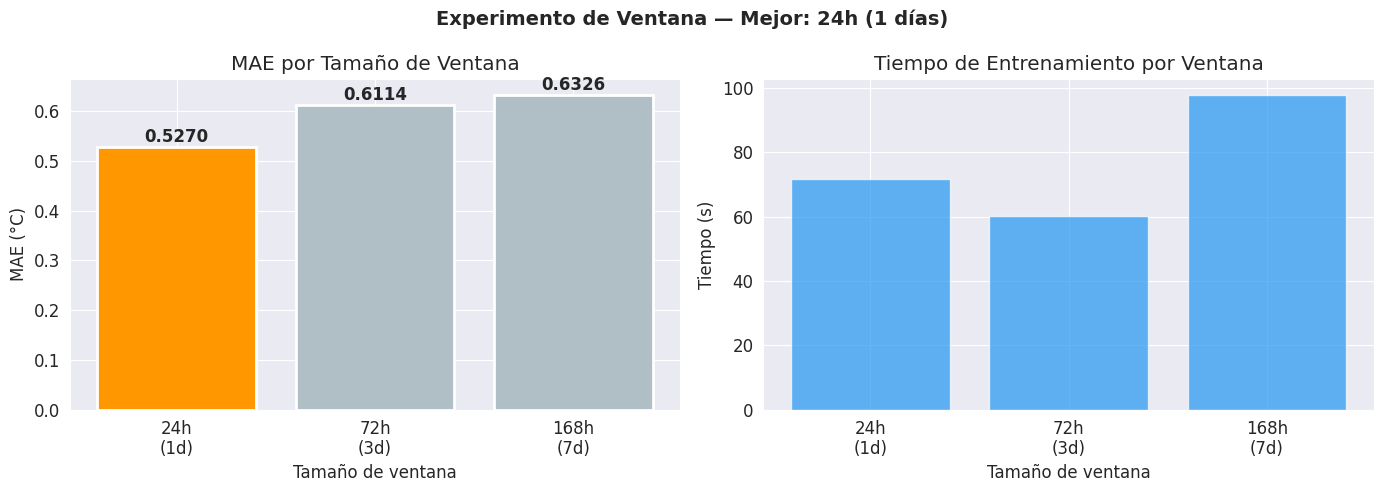

In [ ]:
# ============================================================
# 🔍 Experimento: Tamaño de ventana óptimo
# ============================================================
windows = [24, 72, 168]  # 1 día, 3 días, 1 semana
window_results = {}

print('Experimentando con diferentes tamaños de ventana (GRU)...')
for w in windows:
    tf.random.set_seed(42)

    X_tr, y_tr = create_sequences(train_multi_scaled, w, 1)
    X_te, y_te = create_sequences(test_multi_scaled, w, 1)

    m = models.Sequential([
        layers.GRU(64, input_shape=(w, len(selected_features))),
        layers.Dropout(0.2),
        layers.Dense(1)
    ])
    m.compile(optimizer='adam', loss='mse', metrics=['mae'])

    t0 = time.time()
    m.fit(X_tr, y_tr, epochs=20, batch_size=64,
          validation_split=0.15, verbose=0,
          callbacks=[callbacks.EarlyStopping(patience=3,
                     restore_best_weights=True, verbose=0)])
    elapsed = time.time() - t0

    pred = m.predict(X_te, verbose=0).flatten()
    pred_real = denorm_temp(pred)
    y_real = denorm_temp(y_te)

    mae = mean_absolute_error(y_real, pred_real)
    window_results[w] = {'MAE': mae, 'time': elapsed, 'params': m.count_params()}
    print(f'  Ventana={w:>3}h ({w//24}d) | MAE: {mae:.4f}°C | Tiempo: {elapsed:.1f}s | Params: {m.count_params():,}')

# Gráfico de comparación
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

w_labels = [f'{w}h\n({w//24}d)' for w in windows]
maes = [window_results[w]['MAE'] for w in windows]
times = [window_results[w]['time'] for w in windows]

colors_bar = [COLORS['gru'] if m == min(maes) else '#B0BEC5' for m in maes]
axes[0].bar(w_labels, maes, color=colors_bar, edgecolor='white', linewidth=2)
axes[0].set_ylabel('MAE (°C)')
axes[0].set_xlabel('Tamaño de ventana')
axes[0].set_title('MAE por Tamaño de Ventana')
for i, v in enumerate(maes):
    axes[0].text(i, v + 0.01, f'{v:.4f}', ha='center', fontweight='bold')

axes[1].bar(w_labels, times, color=COLORS['lstm'], alpha=0.7, edgecolor='white')
axes[1].set_ylabel('Tiempo (s)')
axes[1].set_xlabel('Tamaño de ventana')
axes[1].set_title('Tiempo de Entrenamiento por Ventana')

best_w = min(window_results, key=lambda k: window_results[k]['MAE'])
plt.suptitle(f'Experimento de Ventana — Mejor: {best_w}h ({best_w//24} días)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

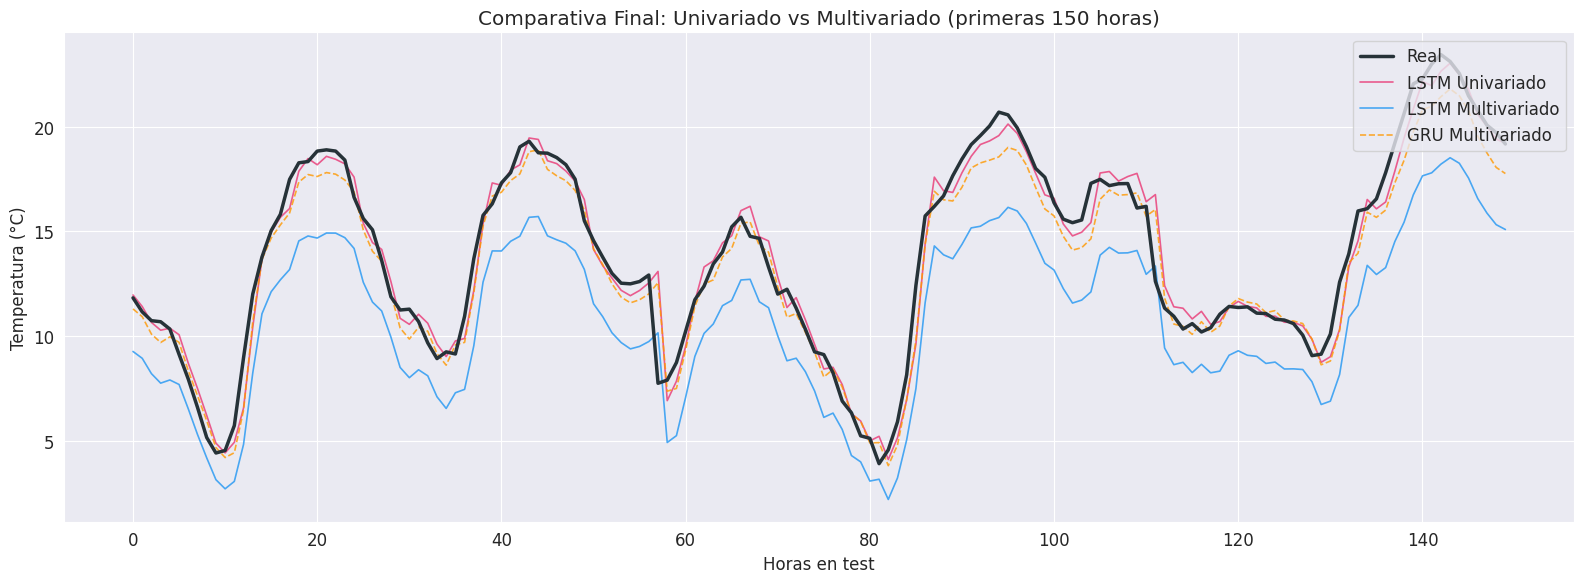

In [ ]:
# ============================================================
# 📊 Visualización final comparativa
# ============================================================
fig, ax = plt.subplots(figsize=(16, 6))

n_show = 150
ax.plot(y_test_real_m[:n_show], color=COLORS['actual'],
        linewidth=2.5, label='Real', zorder=5)
ax.plot(y_pred_real[:n_show], color=COLORS['pred'],
        linewidth=1.2, alpha=0.7, label='LSTM Univariado')
ax.plot(pred_lstm_real[:n_show], color=COLORS['lstm'],
        linewidth=1.2, alpha=0.8, label='LSTM Multivariado')
ax.plot(pred_gru_real[:n_show], color=COLORS['gru'],
        linewidth=1.2, alpha=0.8, label='GRU Multivariado', linestyle='--')

ax.set_xlabel('Horas en test')
ax.set_ylabel('Temperatura (°C)')
ax.set_title('Comparativa Final: Univariado vs Multivariado (primeras 150 horas)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

### 💡 Conclusiones del Ejemplo 2

1. **GRU ofrece rendimiento comparable a LSTM** con ~25% menos parámetros y entrenamiento más rápido.
2. **El enfoque multivariado no siempre mejora** el univariado. Depende de cuán correlacionadas estén las variables adicionales con el target.
3. **El tamaño de ventana importa** — ventanas muy cortas pierden contexto, ventanas muy largas agregan ruido y costo computacional.
4. **LSTM vs GRU**: Para este problema, las diferencias son pequeñas. La regla sigue: empieza con GRU, escala a LSTM si necesitas más.

> ⚡ **Próximo desafío:** ¿Y si en lugar de predecir, queremos **clasificar** secuencias? Pasemos del forecasting a la clasificación.

---

## 🔬 Ejemplo 3 (Avanzado): Clasificación de Señales — Benchmark RNN/LSTM/GRU/BiLSTM

**Objetivo:** Comparar las 4 arquitecturas recurrentes en una tarea de **clasificación de secuencias**, usando un dataset sintético de formas de onda.

**Cambio de paradigma:** En los Ejemplos 1 y 2 hicimos **forecasting** (many-to-one con salida continua). Ahora hacemos **clasificación** (many-to-one con salida categórica).

**¿Por qué Bidirectional?** En clasificación, tenemos **toda la secuencia disponible** antes de decidir. A diferencia del forecasting (donde no podemos mirar el futuro), aquí BiLSTM puede leer la señal en ambas direcciones.

**Dataset:** 5 tipos de señales sintéticas (5000 muestras, 128 timesteps cada una).

| Clase | Señal | Característica |
|---|---|---|
| 0 | Sinusoidal | Frecuencia y fase variables |
| 1 | Cuadrada | Transiciones abruptas |
| 2 | Diente de Sierra | Rampas lineales |
| 3 | Chirp | Frecuencia que aumenta en el tiempo |
| 4 | Ruido Gaussiano | Sin patrón periódico |

In [ ]:
# ============================================================
# 🎵 Generación del dataset de señales sintéticas
# ============================================================
np.random.seed(42)

N_SAMPLES = 1000      # Muestras por clase
SEQ_LEN = 128         # Longitud de cada señal
N_CLASSES = 5
NOISE_LEVEL = 0.05    # Ruido añadido

class_names = ['Sinusoidal', 'Cuadrada', 'Diente de Sierra', 'Chirp', 'Ruido']
t = np.linspace(0, 1, SEQ_LEN)

signals = []
labels = []

for i in range(N_SAMPLES):
    # Clase 0: Sinusoidal (freq aleatoria 1-3 Hz, fase aleatoria)
    freq = np.random.uniform(1, 3)
    phase = np.random.uniform(0, 2 * np.pi)
    s = np.sin(2 * np.pi * freq * t + phase)
    signals.append(s + np.random.normal(0, NOISE_LEVEL, SEQ_LEN))
    labels.append(0)

    # Clase 1: Cuadrada
    freq = np.random.uniform(1, 3)
    phase = np.random.uniform(0, 2 * np.pi)
    s = np.sign(np.sin(2 * np.pi * freq * t + phase))
    signals.append(s + np.random.normal(0, NOISE_LEVEL, SEQ_LEN))
    labels.append(1)

    # Clase 2: Diente de Sierra (sawtooth)
    freq = np.random.uniform(1, 3)
    phase = np.random.uniform(0, 1)
    s = 2 * ((freq * t + phase) % 1) - 1
    signals.append(s + np.random.normal(0, NOISE_LEVEL, SEQ_LEN))
    labels.append(2)

    # Clase 3: Chirp (frecuencia creciente de f0 a f1)
    f0 = np.random.uniform(0.5, 1.5)
    f1 = np.random.uniform(3, 6)
    s = np.sin(2 * np.pi * (f0 * t + (f1 - f0) * t**2 / 2))
    signals.append(s + np.random.normal(0, NOISE_LEVEL, SEQ_LEN))
    labels.append(3)

    # Clase 4: Ruido Gaussiano (sin estructura)
    amplitude = np.random.uniform(0.5, 1.5)
    s = np.random.normal(0, amplitude, SEQ_LEN)
    signals.append(s)
    labels.append(4)

X_signals = np.array(signals)
y_signals = np.array(labels)

print(f'Dataset de señales:')
print(f'  X shape: {X_signals.shape}')
print(f'  Clases: {N_CLASSES} ({", ".join(class_names)})')
print(f'  Muestras por clase: {N_SAMPLES}')
print(f'  Total: {len(X_signals)} señales de {SEQ_LEN} timesteps')

Dataset de señales:
  X shape: (5000, 128)
  Clases: 5 (Sinusoidal, Cuadrada, Diente de Sierra, Chirp, Ruido)
  Muestras por clase: 1000
  Total: 5000 señales de 128 timesteps


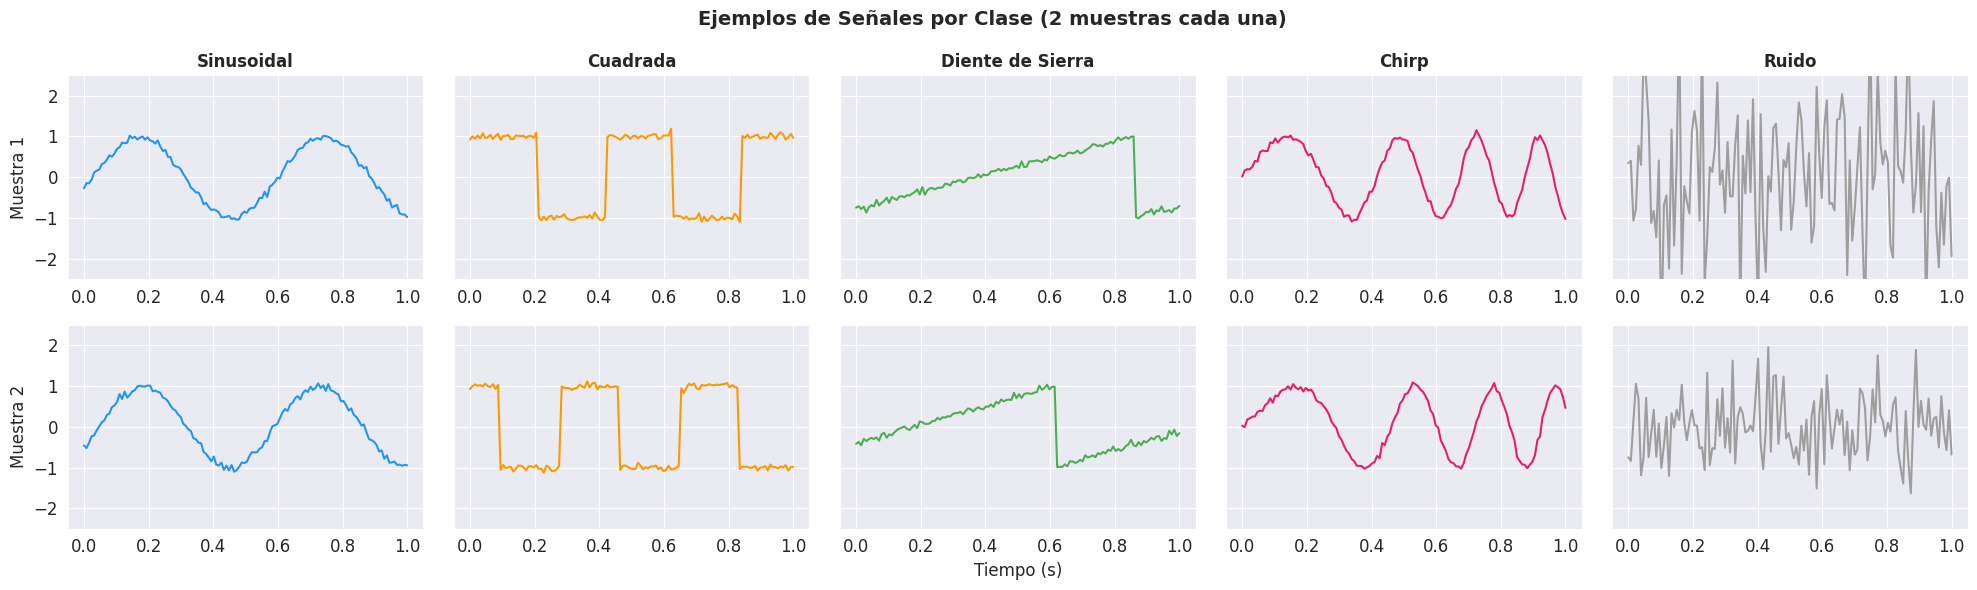

In [ ]:
# ============================================================
# 📊 Visualización de señales por clase
# ============================================================
fig, axes = plt.subplots(2, 5, figsize=(20, 6))
class_colors = ['#2196F3', '#FF9800', '#4CAF50', '#E91E63', '#9E9E9E']

for cls in range(N_CLASSES):
    cls_indices = np.where(y_signals == cls)[0][:2]  # 2 muestras por clase
    for row, idx in enumerate(cls_indices):
        ax = axes[row, cls]
        ax.plot(t, X_signals[idx], color=class_colors[cls], linewidth=1.5)
        if row == 0:
            ax.set_title(class_names[cls], fontweight='bold', fontsize=12)
        ax.set_ylim(-2.5, 2.5)
        if cls == 0:
            ax.set_ylabel(f'Muestra {row+1}')
        else:
            ax.set_yticklabels([])

axes[1, 2].set_xlabel('Tiempo (s)')
fig.suptitle('Ejemplos de Señales por Clase (2 muestras cada una)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 🔧 Preparación de datos para clasificación
# ============================================================
from sklearn.model_selection import train_test_split as tts

# Normalizar señales con StandardScaler
scaler_sig = StandardScaler()
X_norm = scaler_sig.fit_transform(X_signals)

# Reshape a (samples, timesteps, 1) para las RNN
X_norm = X_norm.reshape(-1, SEQ_LEN, 1)

# Split estratificado 80/20
X_train_sig, X_test_sig, y_train_sig, y_test_sig = tts(
    X_norm, y_signals, test_size=0.2,
    stratify=y_signals, random_state=42
)

# One-hot encoding
y_train_oh = tf.keras.utils.to_categorical(y_train_sig, N_CLASSES)
y_test_oh = tf.keras.utils.to_categorical(y_test_sig, N_CLASSES)

print(f'Datos de entrenamiento:')
print(f'  X_train: {X_train_sig.shape}')
print(f'  y_train: {y_train_oh.shape}')
print(f'\nDatos de test:')
print(f'  X_test: {X_test_sig.shape}')
print(f'  y_test: {y_test_oh.shape}')
print(f'\nDistribución de clases (train):')
for cls in range(N_CLASSES):
    n = np.sum(y_train_sig == cls)
    print(f'  {class_names[cls]}: {n} ({n/len(y_train_sig)*100:.1f}%)')

Datos de entrenamiento:
  X_train: (4000, 128, 1)
  y_train: (4000, 5)

Datos de test:
  X_test: (1000, 128, 1)
  y_test: (1000, 5)

Distribución de clases (train):
  Sinusoidal: 800 (20.0%)
  Cuadrada: 800 (20.0%)
  Diente de Sierra: 800 (20.0%)
  Chirp: 800 (20.0%)
  Ruido: 800 (20.0%)


In [ ]:
# ============================================================
# 🏗️ Definición de los 4 modelos recurrentes
# ============================================================

def build_classifier(model_type, input_shape=(SEQ_LEN, 1), n_classes=N_CLASSES):
    '''Construye un clasificador recurrente.

    Args:
        model_type: 'SimpleRNN', 'LSTM', 'GRU' o 'BiLSTM'
        input_shape: forma de entrada (timesteps, features)
        n_classes: número de clases
    '''
    tf.random.set_seed(42)
    model = models.Sequential(name=model_type)

    if model_type == 'SimpleRNN':
        model.add(layers.SimpleRNN(64, input_shape=input_shape))
    elif model_type == 'LSTM':
        model.add(layers.LSTM(64, input_shape=input_shape))
    elif model_type == 'GRU':
        model.add(layers.GRU(64, input_shape=input_shape))
    elif model_type == 'BiLSTM':
        model.add(layers.Bidirectional(
            layers.LSTM(64), input_shape=input_shape
        ))

    model.add(layers.Dense(32, activation='relu'))
    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(n_classes, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Mostrar arquitecturas
model_types = ['SimpleRNN', 'LSTM', 'GRU', 'BiLSTM']
print('Parámetros por modelo:')
print('-' * 40)
for mt in model_types:
    m = build_classifier(mt)
    print(f'  {mt:<12} → {m.count_params():>8,} parámetros')
print('-' * 40)

Parámetros por modelo:
----------------------------------------
  SimpleRNN    →    6,469 parámetros
  LSTM         →   19,141 parámetros
  GRU          →   15,109 parámetros
  BiLSTM       →   38,085 parámetros
----------------------------------------


In [ ]:
# ============================================================
# 🚀 Entrenamiento de los 4 modelos
# ============================================================
EPOCHS_CLS = 30
BATCH_CLS = 64

results = {}

for mt in model_types:
    print(f'\n{"="*50}')
    print(f'Entrenando: {mt}')
    print(f'{"="*50}')

    model = build_classifier(mt)

    t0 = time.time()
    history = model.fit(
        X_train_sig, y_train_oh,
        epochs=EPOCHS_CLS,
        batch_size=BATCH_CLS,
        validation_split=0.15,
        callbacks=[
            callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=0)
        ],
        verbose=0
    )
    elapsed = time.time() - t0

    # Evaluar en test
    loss, acc = model.evaluate(X_test_sig, y_test_oh, verbose=0)

    results[mt] = {
        'model': model,
        'history': history,
        'accuracy': acc,
        'loss': loss,
        'time': elapsed,
        'params': model.count_params(),
        'epochs': len(history.history['loss'])
    }

    print(f'  Accuracy: {acc:.4f} | Loss: {loss:.4f} | '
          f'Tiempo: {elapsed:.1f}s | Épocas: {results[mt]["epochs"]}')

print(f'\n{"="*50}')
print('✅ Entrenamiento completado')


Entrenando: SimpleRNN
  Accuracy: 0.9880 | Loss: 0.0938 | Tiempo: 22.7s | Épocas: 22

Entrenando: LSTM
  Accuracy: 0.9980 | Loss: 0.0153 | Tiempo: 14.1s | Épocas: 16

Entrenando: GRU
  Accuracy: 1.0000 | Loss: 0.0001 | Tiempo: 20.7s | Épocas: 30

Entrenando: BiLSTM
  Accuracy: 0.9980 | Loss: 0.0121 | Tiempo: 14.7s | Épocas: 14

✅ Entrenamiento completado


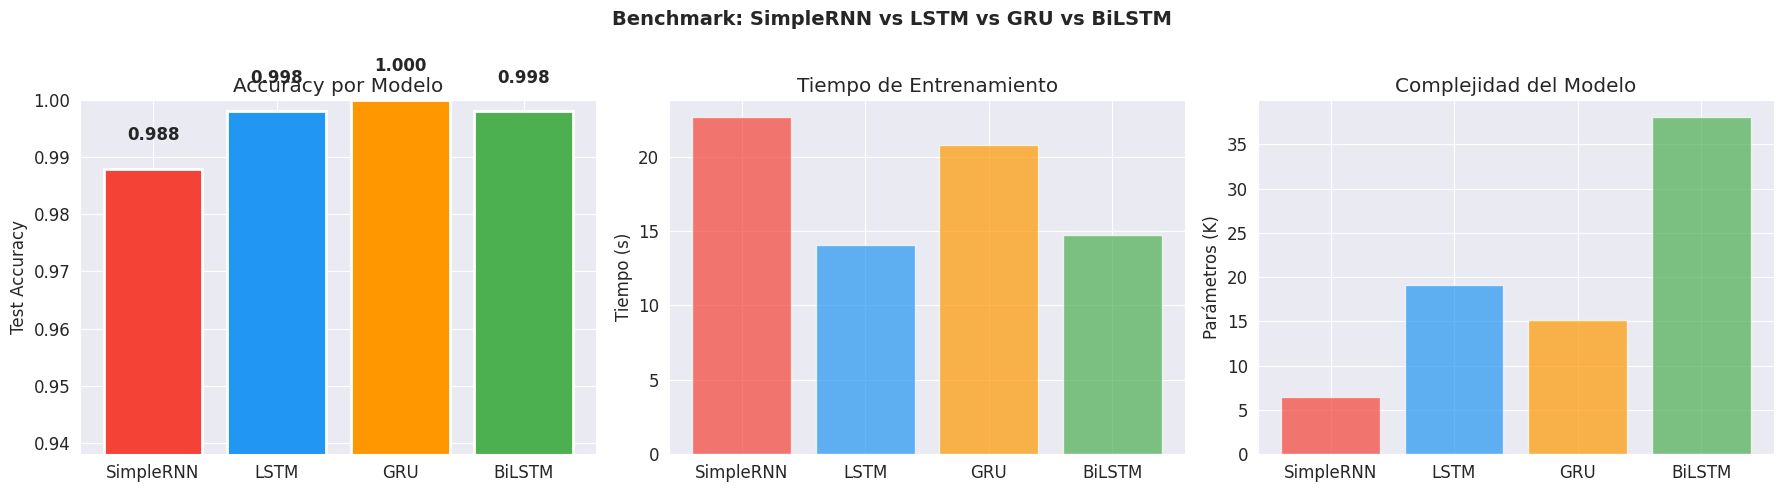


             Accuracy     Loss         Params       Tiempo (s)   Épocas  
---------------------------------------------------------------------------
SimpleRNN    0.9880       0.0938       6,469        22.7         22      
LSTM         0.9980       0.0153       19,141       14.1         16      
GRU          1.0000       0.0001       15,109       20.7         30      
BiLSTM       0.9980       0.0121       38,085       14.7         14      

🏆 Mejor modelo: GRU (accuracy: 1.0000)


In [ ]:
# ============================================================
# 📊 Comparación de los 4 modelos
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

model_colors = [COLORS['rnn'], COLORS['lstm'], COLORS['gru'], COLORS['bilstm']]
accs = [results[mt]['accuracy'] for mt in model_types]
times = [results[mt]['time'] for mt in model_types]
params = [results[mt]['params'] for mt in model_types]

# Accuracy
bars = axes[0].bar(model_types, accs, color=model_colors, edgecolor='white', linewidth=2)
axes[0].set_ylabel('Test Accuracy')
axes[0].set_title('Accuracy por Modelo')
axes[0].set_ylim(min(accs) - 0.05, 1.0)
for bar, v in zip(bars, accs):
    axes[0].text(bar.get_x() + bar.get_width()/2, v + 0.005,
                 f'{v:.3f}', ha='center', fontweight='bold')

# Tiempo
axes[1].bar(model_types, times, color=model_colors, alpha=0.7, edgecolor='white')
axes[1].set_ylabel('Tiempo (s)')
axes[1].set_title('Tiempo de Entrenamiento')

# Parámetros
axes[2].bar(model_types, [p/1000 for p in params], color=model_colors,
            alpha=0.7, edgecolor='white')
axes[2].set_ylabel('Parámetros (K)')
axes[2].set_title('Complejidad del Modelo')

plt.suptitle('Benchmark: SimpleRNN vs LSTM vs GRU vs BiLSTM',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Tabla resumen
print('\n' + '=' * 75)
print(f'{"":<12} {"Accuracy":<12} {"Loss":<12} {"Params":<12} {"Tiempo (s)":<12} {"Épocas":<8}')
print('-' * 75)
for mt in model_types:
    r = results[mt]
    print(f'{mt:<12} {r["accuracy"]:<12.4f} {r["loss"]:<12.4f} '
          f'{r["params"]:<12,} {r["time"]:<12.1f} {r["epochs"]:<8}')
print('=' * 75)

best = max(results, key=lambda k: results[k]['accuracy'])
print(f'\n🏆 Mejor modelo: {best} (accuracy: {results[best]["accuracy"]:.4f})')

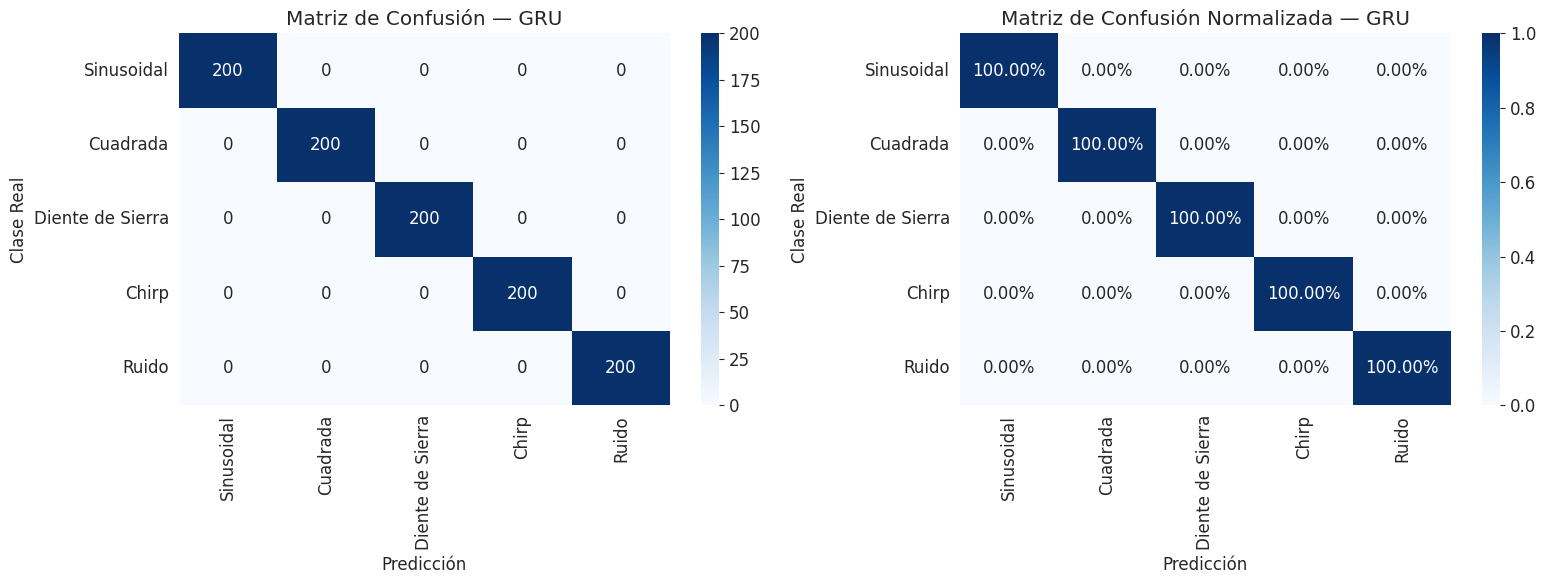


📋 Reporte de Clasificación — GRU
                  precision    recall  f1-score   support

      Sinusoidal     1.0000    1.0000    1.0000       200
        Cuadrada     1.0000    1.0000    1.0000       200
Diente de Sierra     1.0000    1.0000    1.0000       200
           Chirp     1.0000    1.0000    1.0000       200
           Ruido     1.0000    1.0000    1.0000       200

        accuracy                         1.0000      1000
       macro avg     1.0000    1.0000    1.0000      1000
    weighted avg     1.0000    1.0000    1.0000      1000



In [ ]:
# ============================================================
# 🔍 Matriz de confusión del mejor modelo
# ============================================================
best_model = results[best]['model']
y_pred_cls = best_model.predict(X_test_sig, verbose=0)
y_pred_labels = np.argmax(y_pred_cls, axis=1)

cm = confusion_matrix(y_test_sig, y_pred_labels)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[0])
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Clase Real')
axes[0].set_title(f'Matriz de Confusión — {best}')

# Heatmap normalizado
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[1])
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Clase Real')
axes[1].set_title(f'Matriz de Confusión Normalizada — {best}')

plt.tight_layout()
plt.show()

# Reporte de clasificación
print(f'\n📋 Reporte de Clasificación — {best}')
print('=' * 65)
print(classification_report(y_test_sig, y_pred_labels,
                            target_names=class_names, digits=4))

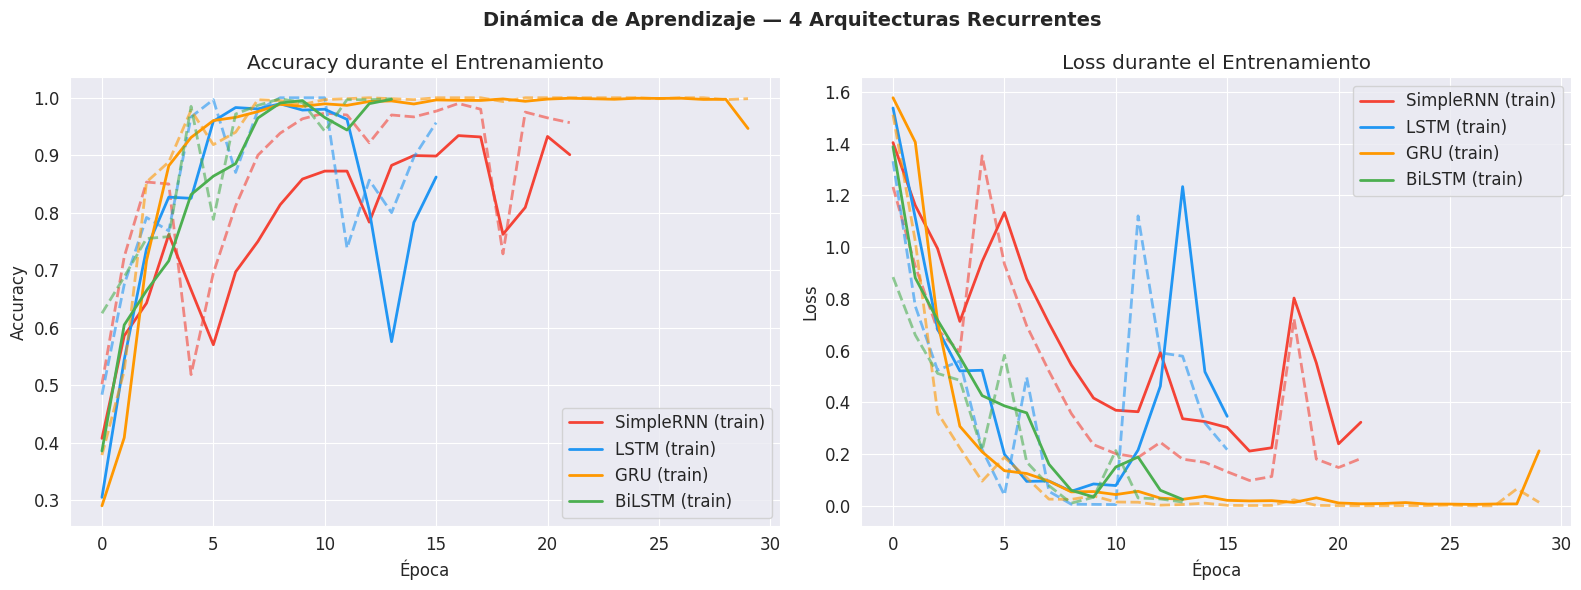

Observaciones:
  • SimpleRNN: Converge rápido pero a un techo más bajo
  • LSTM/GRU: Rendimiento similar, GRU ligeramente más rápido
  • BiLSTM: Mejor accuracy (lee en ambas direcciones)


In [ ]:
# ============================================================
# 📈 Curvas de aprendizaje de los 4 modelos
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for mt, color in zip(model_types, model_colors):
    h = results[mt]['history']
    axes[0].plot(h.history['accuracy'], color=color,
                 linewidth=2, label=f'{mt} (train)')
    axes[0].plot(h.history['val_accuracy'], color=color,
                 linewidth=2, linestyle='--', alpha=0.6)

axes[0].set_xlabel('Época')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy durante el Entrenamiento')
axes[0].legend(loc='lower right')

for mt, color in zip(model_types, model_colors):
    h = results[mt]['history']
    axes[1].plot(h.history['loss'], color=color,
                 linewidth=2, label=f'{mt} (train)')
    axes[1].plot(h.history['val_loss'], color=color,
                 linewidth=2, linestyle='--', alpha=0.6)

axes[1].set_xlabel('Época')
axes[1].set_ylabel('Loss')
axes[1].set_title('Loss durante el Entrenamiento')
axes[1].legend(loc='upper right')

plt.suptitle('Dinámica de Aprendizaje — 4 Arquitecturas Recurrentes',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Observaciones:')
print('  • SimpleRNN: Converge rápido pero a un techo más bajo')
print('  • LSTM/GRU: Rendimiento similar, GRU ligeramente más rápido')
print('  • BiLSTM: Mejor accuracy (lee en ambas direcciones)')

### 💡 Conclusiones del Ejemplo 3

1. **BiLSTM es el mejor para clasificación de secuencias completas** — Puede leer la señal en ambas direcciones, capturando patrones que un LSTM unidireccional perdería.
2. **SimpleRNN confirma su debilidad** — El vanishing gradient limita su capacidad, incluso con señales de solo 128 pasos.
3. **GRU y LSTM son comparables** — La diferencia suele ser menor al 1% en accuracy. GRU tiene menos parámetros.
4. **Bidirectional NO es válido para forecasting** — Solo funciona cuando tienes la secuencia completa antes de clasificar.

> 📝 **Nota:** Este mismo dataset de señales lo usaremos en el Notebook 10-B para comparar CNN 1D, TCN y Transformers contra estos resultados recurrentes.

---

## ✅ Checklist de Verificación — Series de Tiempo con Deep Learning

| # | Verificación | Estado |
|---|---|---|
| 1 | Split cronológico (nunca aleatorio para forecasting) | ✅ |
| 2 | Normalización con `fit` solo en datos de entrenamiento | ✅ |
| 3 | Ventanas deslizantes con función `create_sequences` reproducible | ✅ |
| 4 | Shapes correctos: `(samples, timesteps, features)` | ✅ |
| 5 | Baseline naive calculado antes de evaluar el modelo | ✅ |
| 6 | EarlyStopping + ReduceLROnPlateau para evitar sobreajuste | ✅ |
| 7 | Métricas apropiadas: MAE/RMSE para forecasting, F1 para clasificación | ✅ |
| 8 | Dropout entre capas recurrentes apiladas | ✅ |
| 9 | Desnormalización antes de calcular métricas interpretables | ✅ |
| 10 | Visualización de predicciones vs valores reales | ✅ |

## 📋 Resumen de Resultados — Sesión 10-A

| Ejemplo | Nivel | Tarea | Arquitectura | Dataset | Resultado Clave |
|---|---|---|---|---|---|
| 1 | 🟢 Básico | Forecasting univariado | LSTM simple | Jena Climate (temp.) | LSTM > Naive baseline |
| 2 | 🟡 Intermedio | Forecasting multivariado | LSTM vs GRU stacked | Jena Climate (4 vars) | GRU ≈ LSTM con 25% menos params |
| 3 | 🔴 Avanzado | Clasificación de señales | SimpleRNN/LSTM/GRU/BiLSTM | Señales sintéticas | BiLSTM > todos los demás |

**Lecciones transversales:**
- La preparación de datos (split, normalización, ventanas) importa más que la arquitectura
- GRU es un excelente punto de partida por su balance rendimiento/eficiencia
- Bidirectional solo cuando tienes la secuencia completa (clasificación, NLP), nunca para forecasting

### 🔮 Siguiente: Sesión 10-B — CNN 1D, TCN y Transformers

En el próximo notebook exploraremos arquitecturas **no recurrentes** para series de tiempo:

| Arquitectura | Idea Central | Ventaja sobre LSTM |
|---|---|---|
| **CNN 1D** | Filtros convolucionales sobre el eje temporal | Paralela, 5-10x más rápida |
| **TCN** | CNN causal + dilatación exponencial | Campo receptivo enorme sin más parámetros |
| **Transformer** | Self-attention global | Cada punto consulta directamente a cualquier otro |

> 🎯 **Reto:** El dataset de clasificación de señales del Ejemplo 3 será atacado con CNN 1D para comparar directamente contra los resultados de BiLSTM.

---

*Notebook generado para el curso IS056B — Ingeniería del Conocimiento | UNCP 2026-II*
*Docente: Msc. Jaime Antonio Huaytalla Pariona*